# ✈️ Onde, quando e por que os voos atrasam no Brasil?

**Análise de 810 mil voos domésticos (out/2025 – set/2026) com dados oficiais da ANAC**

### Pergunta de negócio
Atrasos custam caro: passageiros perdem conexões, companhias pagam assistência material (Resolução ANAC 400) e aeroportos perdem eficiência.
Este estudo responde três perguntas que interessam a **companhias aéreas, administradoras de aeroportos e passageiros**:

1. **Onde** os atrasos se concentram?
2. **Quem** atrasa mais e se essa comparação é justa?
3. **Quando** é mais provável atrasar, e o que isso diz sobre a origem do problema?

### Definições
| Termo | Definição |
|---|---|
| Voo atrasado | chegada **mais de 15 min** após o horário previsto (padrão internacional OTP15) |
| Escopo | voos domésticos de passageiros (`tipo_linha = 'N'`), programados e realizados |
| Fonte | [ANAC – VRA](https://siros.anac.gov.br/siros/registros/diversos/vra/), tratado em DuckDB (`sql/`) |

In [1]:
import sys
sys.path.append("../src")

import duckdb
import pandas as pd
import graficos as g

g.aplicar_estilo()
con = duckdb.connect("../data/voos.duckdb", read_only=True)
sql = lambda q: con.sql(q).df()

## 1. Qualidade dos dados
Antes de qualquer conclusão: quanto do dado bruto é aproveitável?

In [2]:
sql('''
select
    count(*)                                                      as voos_domesticos,
    count(*) filter (where cancelado)                             as cancelados,
    count(*) filter (where not programado)                        as nao_programados,
    count(*) filter (where dado_suspeito)                         as horarios_invalidos,
    (select count(*) from vw_voos_pontualidade)                   as base_analise,
    round(100.0 * (select count(*) from vw_voos_pontualidade) / count(*), 1) as pct_aproveitado
from fct_voos
''')

,voos_domesticos,cancelados,nao_programados,horarios_invalidos,base_analise,pct_aproveitado
0,810634,14415,15832,33,780354,96.3


- **96% dos voos** entram na análise de pontualidade.
- Voos **não programados** são extras, sem horário previsto, então não dá para medir atraso neles.
- 33 voos têm atrasos impossíveis (até 31 dias, ou chegada 1 dia antes do previsto). São erros de registro e foram excluídos.
- ⚠️ A coluna `Justificativa` (causa do atraso) vem **vazia** na base pública. Por isso a análise investiga a causa de forma indireta, pelos padrões de local e horário.

## 2. Visão geral

In [3]:
kpis = sql('''
select
    count(*)                                   as voos,
    avg(atrasado_15::int)                      as pct_atraso_15,
    avg(atrasado_30::int)                      as pct_atraso_30,
    avg(atrasado_60::int)                      as pct_atraso_60,
    median(atraso_chegada_min)                 as mediana_min
from vw_voos_pontualidade
''')
cancel = sql("select avg(cancelado::int) as pct_cancelados from fct_voos where programado")
pd.concat([kpis, cancel], axis=1).style.format({
    "voos": "{:,.0f}", "pct_atraso_15": "{:.1%}", "pct_atraso_30": "{:.1%}",
    "pct_atraso_60": "{:.1%}", "pct_cancelados": "{:.1%}", "mediana_min": "{:.0f} min"})

,voos,pct_atraso_15,pct_atraso_30,pct_atraso_60,mediana_min,pct_cancelados
0,"780,354",16.4%,8.4%,3.1%,-4 min,1.8%


**1 em cada 6 voos chega atrasado** e cerca de 1 em 12 passa de 30 min. O voo típico (mediana) chega **4 min adiantado**, porque as companhias colocam folga na programação.
O problema não é o voo médio, e sim a **cauda**: os atrasos se concentram em lugares e horários específicos.

## 3. Onde: o efeito Guarulhos

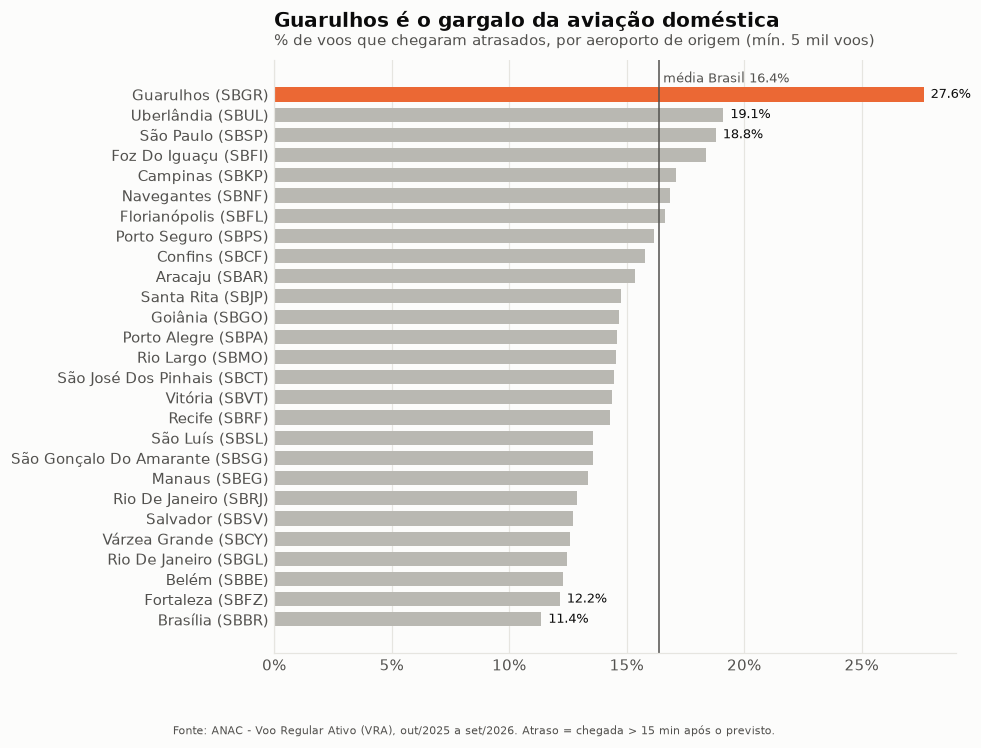

In [4]:
media_br = kpis["pct_atraso_15"].iloc[0]
aeroportos = sql('''
select origem_icao, origem_cidade, count(*) as voos, avg(atrasado_15::int) as pct_atraso
from vw_voos_pontualidade
group by all
having voos >= 5000
order by pct_atraso desc
''')
g.salvar(g.ranking_aeroportos(aeroportos, media=media_br), "01_aeroportos");

In [5]:
sql('''
select
    origem_icao = 'SBGR' or destino_icao = 'SBGR'          as envolve_gru,
    count(*)                                               as voos,
    round(100.0 * count(*) / sum(count(*)) over (), 1)     as pct_dos_voos,
    round(100.0 * sum(atrasado_15::int) / sum(sum(atrasado_15::int)) over (), 1) as pct_dos_atrasos
from vw_voos_pontualidade
group by 1
''')

,envolve_gru,voos,pct_dos_voos,pct_dos_atrasos
0,False,588025,75.4,63.6
1,True,192329,24.6,36.4


**Guarulhos (SBGR)** tem 27,6% dos voos com chegada atrasada, **quase o dobro da média nacional** e bem acima do 2º colocado.
As 10 rotas mais atrasadas do país **saem todas de GRU**:

In [6]:
sql('''
select rota, origem_cidade || ' → ' || destino_cidade as trecho, count(*) as voos,
       round(100 * avg(atrasado_15::int), 1) as pct_atraso
from vw_voos_pontualidade
group by all
having voos >= 2000
order by pct_atraso desc
limit 10
''')

,rota,trecho,voos,pct_atraso
0,SBGR-SBEG,GUARULHOS → MANAUS,2066,34.9
1,SBGR-SBFZ,GUARULHOS → FORTALEZA,3802,33.7
2,SBGR-SBCG,GUARULHOS → CAMPO GRANDE,2198,31.5
3,SBGR-SBFL,GUARULHOS → FLORIANÓPOLIS,3117,31.3
4,SBGR-SBVT,GUARULHOS → VITÓRIA,3061,30.8
5,SBGR-SBBR,GUARULHOS → BRASÍLIA,4114,30.1
6,SBGR-SBCF,GUARULHOS → CONFINS,4800,29.1
7,SBGR-SBGO,GUARULHOS → GOIÂNIA,2730,29.0
8,SBGR-SBSV,GUARULHOS → SALVADOR,4217,29.0
9,SBFI-SBGR,FOZ DO IGUAÇU → GUARULHOS,2541,28.8


## 4. Quem: o ranking das companhias engana

In [7]:
empresas = sql('''
select
    grupo_empresa,
    count(*)                                                       as voos,
    avg(atrasado_15::int)                                          as todos,
    avg(atrasado_15::int) filter (where origem_icao <> 'SBGR'
                                    and destino_icao <> 'SBGR')    as sem_gru,
    avg((origem_icao = 'SBGR')::int)                               as share_partidas_gru
from vw_voos_pontualidade
where grupo_empresa <> 'Outras'
group by 1
''')
empresas.style.format({"voos": "{:,.0f}", "todos": "{:.1%}", "sem_gru": "{:.1%}", "share_partidas_gru": "{:.1%}"})

,grupo_empresa,voos,todos,sem_gru,share_partidas_gru
0,LATAM,"270,946",19.7%,14.4%,21.8%
1,Azul,"274,958",15.1%,15.0%,3.1%
2,Gol,"230,150",13.9%,11.5%,12.0%


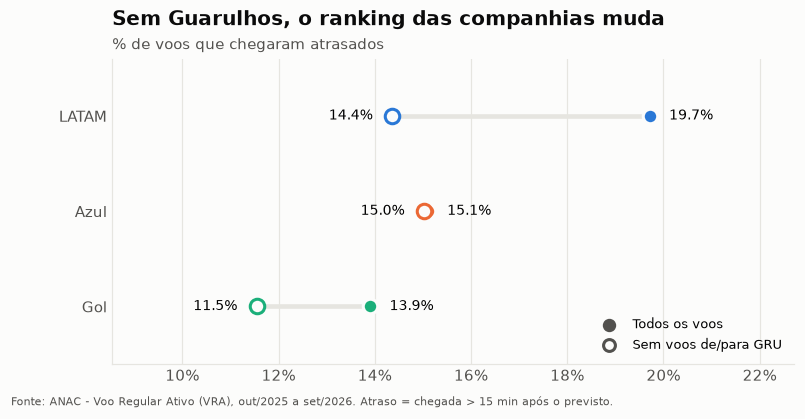

In [8]:
g.salvar(g.empresas_com_e_sem_gru(empresas), "02_empresas_gru");

In [9]:
# Mesma companhia, aeroportos diferentes: comparação justa (mesmas condições de pista e pátio)
sql('''
pivot (
    select origem_icao, grupo_empresa, round(100 * avg(atrasado_15::int), 1) as p
    from vw_voos_pontualidade
    where origem_icao in ('SBGR','SBSP','SBKP','SBBR','SBCF','SBGL','SBRJ','SBRF')
      and grupo_empresa <> 'Outras'
    group by all
) on grupo_empresa using first(p)
order by origem_icao
''')

,origem_icao,Azul,Gol,LATAM
0,SBBR,16.8,9.5,11.4
1,SBCF,15.3,13.4,21.6
2,SBGL,15.7,10.9,14.4
3,SBGR,15.6,22.6,31.6
4,SBKP,17.5,12.0,9.3
5,SBRF,14.6,12.5,14.9
6,SBRJ,16.0,10.1,12.9
7,SBSP,20.5,16.6,20.3


Olhando só o total, a **LATAM** parece a companhia mais atrasada (19,7%). Mas **22% das partidas da LATAM saem de Guarulhos**, contra 3% da Azul.
Quando os voos de/para GRU saem da conta, **a LATAM passa à frente da Azul** e a diferença diminui muito.

Esse é um caso clássico de **variável de confusão**: comparar companhias sem controlar o aeroporto pune quem opera no aeroporto mais congestionado.
Mesmo assim, **dentro de GRU a LATAM atrasa 31,6%, o dobro da Azul (15,6%)**. A operação dela no seu principal hub merece um diagnóstico próprio.

## 5. Quando: o efeito bola de neve

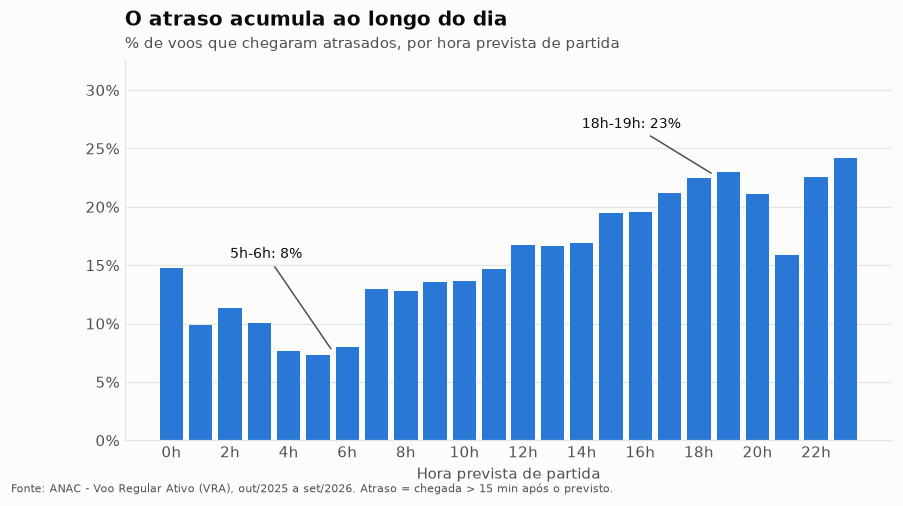

In [10]:
por_hora = sql('''
select hora_partida_prevista as hora, count(*) as voos, avg(atrasado_15::int) as pct_atraso
from vw_voos_pontualidade
group by 1 order by 1
''')
g.salvar(g.atraso_por_hora(por_hora), "03_hora");

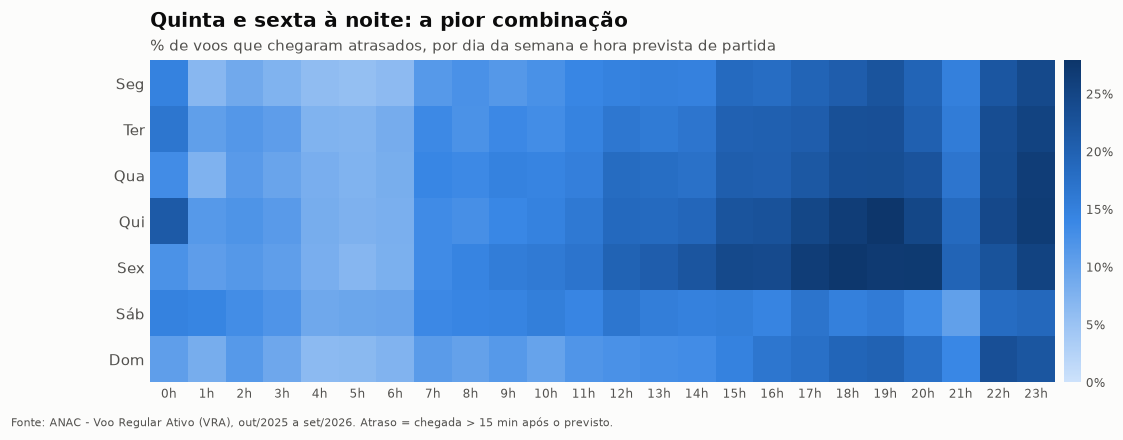

In [11]:
dia_hora = sql('''
select dia_semana, hora_partida_prevista as hora, avg(atrasado_15::int) as pct_atraso
from vw_voos_pontualidade
group by all
''')
nomes = {1: "Seg", 2: "Ter", 3: "Qua", 4: "Qui", 5: "Sex", 6: "Sáb", 7: "Dom"}
pivot = (dia_hora.pivot(index="dia_semana", columns="hora", values="pct_atraso")
         .rename(index=nomes))
g.salvar(g.heatmap_dia_hora(pivot), "04_dia_hora");

In [12]:
sql('''
select
    case when atraso_partida_min > 15 then 'Saiu atrasado (>15 min)' else 'Saiu no horário' end as partida,
    count(*)                                                   as voos,
    round(100 * avg(atrasado_15::int), 1)                      as pct_chegou_atrasado,
    median(atraso_chegada_min - atraso_partida_min)            as min_recuperados_no_ar
from vw_voos_pontualidade
where atraso_partida_min is not null
group by 1
''')

,partida,voos,pct_chegou_atrasado,min_recuperados_no_ar
0,Saiu atrasado (>15 min),129947,79.5,-4.0
1,Saiu no horário,650407,3.8,-4.0


- Voos das **5h–6h** atrasam ~8%; os das **17h–19h**, mais de 21%. Os primeiros voos do dia saem com a aeronave já no pátio. Os seguintes **herdam o atraso** das etapas anteriores, como uma bola de neve.
- **Quinta e sexta à noite** são a pior combinação da semana. **Sábado e domingo** são os dias mais pontuais.
- **80% dos voos que saem atrasados chegam atrasados.** A mediana recuperada no ar é de só 4 min. O atraso **se decide no solo** (embarque, pátio, conexões), não durante o voo.

,data_voo,pct_atraso
71,2025-12-11 00:00:00,64.8%
70,2025-12-10 00:00:00,64.5%
190,2026-04-09 00:00:00,47.0%
72,2025-12-12 00:00:00,46.4%
69,2025-12-09 00:00:00,45.5%
254,2026-06-12 00:00:00,42.4%
73,2025-12-13 00:00:00,40.7%
335,2026-09-01 00:00:00,40.7%


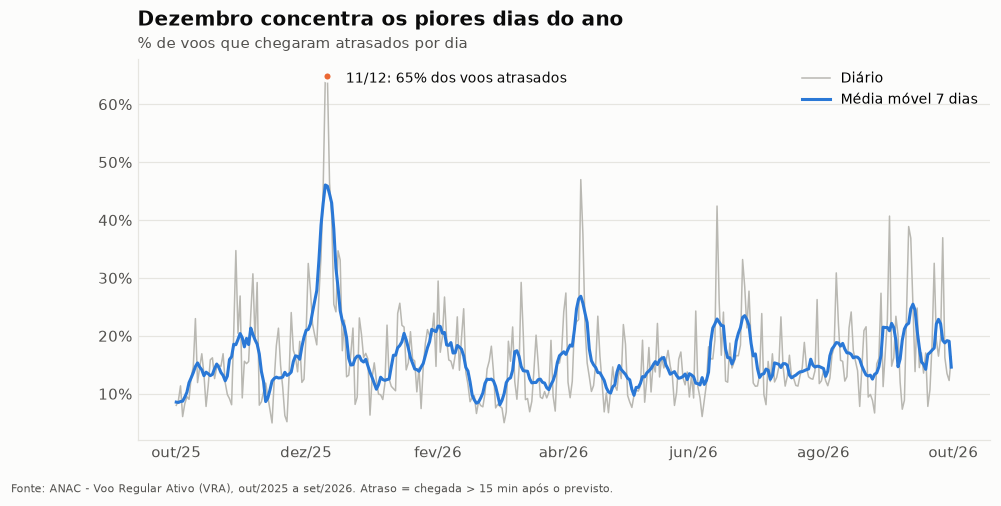

In [13]:
diario = sql('''
select data_voo, avg(atrasado_15::int) as pct_atraso
from vw_voos_pontualidade
group by 1 order by 1
''')
diario["media_7d"] = diario["pct_atraso"].rolling(7, center=True, min_periods=4).mean()
pior = diario.loc[diario["pct_atraso"].idxmax()]
anot = {pior["data_voo"]: f"{pior['data_voo']:%d/%m}: {pior['pct_atraso']:.0%} dos voos atrasados"}
g.salvar(g.serie_diaria(diario, anot), "05_serie_diaria");
diario.nlargest(8, "pct_atraso")[["data_voo", "pct_atraso"]].style.format({"pct_atraso": "{:.1%}"})

**Dezembro** foi o pior mês (25,8%), puxado por uma sequência de **9 a 13/dez/2025**, quando até 65% dos voos atrasaram em um único dia.
A base não traz a causa. O próximo passo seria cruzar essas datas com dados meteorológicos (INMET/METAR) ou com notícias de eventos operacionais.

## 6. Quanto custa?

In [14]:
sql('''
select
    round(sum(greatest(atraso_chegada_min, 0)) / 60)                     as horas_de_atraso_aeronave,
    round(sum(greatest(atraso_chegada_min, 0) * assentos) / 60 / 1e6, 1) as milhoes_assento_hora
from vw_voos_pontualidade
''')

,horas_de_atraso_aeronave,milhoes_assento_hora
0,119186.0,19.7


Em 12 meses foram **~119 mil horas de atraso de aeronave** e quase **20 milhões de assento-horas** perdidas.
É um limite superior, porque considera todos os assentos ocupados. Mesmo assim, mostra a escala do problema: cada ponto percentual de pontualidade recuperado vale centenas de milhares de horas de passageiros.

## 7. Conclusões e recomendações

| # | Achado | Recomendação | Para quem |
|---|---|---|---|
| 1 | **GRU atrasa quase 2× a média** e concentra as 10 piores rotas | Priorizar GRU em investimento de capacidade (pátio, slots, posições de embarque) e revisar a programação de pico | GRU Airport / ANAC |
| 2 | **Rankings de companhias sem controle de aeroporto enganam** | Publicar indicadores de pontualidade **ajustados por aeroporto** | ANAC / imprensa |
| 3 | **LATAM em GRU: 31,6% de atraso**, 2× a Azul no mesmo aeroporto | Diagnóstico do turnaround no hub (tempo de solo, conexões) | LATAM |
| 4 | **O atraso cresce ao longo do dia** e quase nunca é recuperado no ar | Mais folga entre etapas na tarde/noite e aeronaves reserva nos hubs | Companhias |
| 5 | **Voos das 5h–6h atrasam ~3× menos** que os das 18h–19h (8% vs. 23%) | Quem tem compromisso ou conexão deve preferir o primeiro voo do dia | Passageiros |

### Limitações
- Sem a causa do atraso (`Justificativa` vazia na base pública) e sem prefixo da aeronave, não dá para rastrear a propagação exata entre etapas.
- A métrica de chegada (OTP15) é sensível à folga que cada companhia põe na programação (*schedule padding*).
- Os resultados são de 12 meses. Para afirmar tendência, é preciso estender a série (o pipeline aceita qualquer período desde 2000).

### Próximos passos
- Cruzar com dados meteorológicos (METAR) para separar clima de operação.
- Modelo de classificação para prever a probabilidade de atraso de um voo no momento da compra.